# Stage 2 - Subgraph generation and Hamiltonian path verification

Generic code for generating a solvable subgraph from pairwise read-overlap alignments, and for
confirming classically that the subgraph contains a Hamiltonian path before it is handed to the
quantum solver.

The procedure is the same for **every** subgraph reported in this study; only the input alignment
file and the target node count change. It is demonstrated here on the **24-node African swine
fever virus graph** (SRA `SRR27477754`), which is the worked example used throughout.

**Input.** `pairwise_alignments.txt` - one record per scored read pair, written as

```
('<aligned sequence>', <alignment score>, <read i>, <read j>)
```

where the score is the suffix/prefix overlap between the two reads. This file comes from the
all-pairs overlap scoring stage, **not** from `multithread_alignment.py`, which performs
near-duplicate removal only and writes bare read sequences.

**Output.** The weighted adjacency matrix of the retained subgraph, which is the single artefact
passed to the quantum stage, plus the classical Hamiltonian path used as the reference solution.

**Pipeline position.** reads -> Read preprocessing and aligments (1_multithread_aligment.py) -> **this notebook** ->
quantum solver -> contig generation (3_contig_generation.ipynb).

In [2]:
# Setup: imports and the graph drawing helper used throughout.
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np


def show_wgraph(G):
    """Draw a weighted directed graph with its edge weights labelled."""
    plt.figure()
    pos = nx.spring_layout(G)
    weight_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw(G, pos, font_color='white', font_size=6, node_shape='s',
            node_size=70, with_labels=True)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=weight_labels, font_size=6)

alignment records read: 276
counts: [ 1  2 27 37 83 44 40 17 20  5]
bin edges: [ 6.   7.5  9.  10.5 12.  13.5 15.  16.5 18.  19.5 21. ]


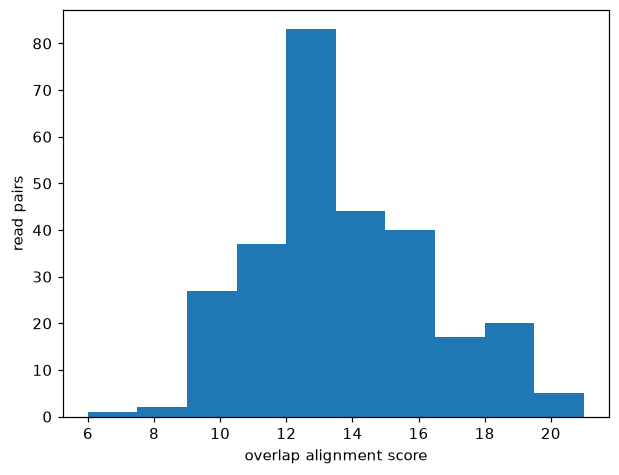

In [ ]:
# Read the pairwise alignment records and inspect the distribution of overlap scores.
# Each record is ('<aligned sequence>', score, read_i, read_j); the score becomes the
# weight of the directed edge read_i -> read_j. The histogram shows where the useful
# overlaps sit and guides the choice of SCORE_THRESHOLD in the next cell.
ALIGNMENT_FILE = "pairwise_alignment.txt"

scores = []
edge_source = []
edge_target = []
raw_records = []

with open(ALIGNMENT_FILE, 'r') as file:
    for line in file:
        raw_records.append(line.strip())
        columns = line.split(',')
        scores.append(columns[1])
        edge_source.append(columns[2])
        edge_target.append(columns[3].split(')')[0].strip())

scores = np.array(scores, dtype=float)
edge_source = np.array(edge_source, dtype=float)
edge_target = np.array(edge_target, dtype=float)
print("alignment records read:", len(scores))

counts, bins = np.histogram(scores)
print("counts:", counts)
print("bin edges:", bins)
plt.hist(bins[:-1], bins, weights=counts)
plt.xlabel("overlap alignment score")
plt.ylabel("read pairs")
plt.show()

In [ ]:
# Build the directed overlap graph: each read is a node, each retained alignment is a
# weighted edge whose weight is the overlap score. Raising SCORE_THRESHOLD discards
SCORE_THRESHOLD = 0      # edges are kept when score > SCORE_THRESHOLD

overlap_graph = nx.DiGraph()
for i in range(len(scores)):
    if scores[i] > SCORE_THRESHOLD:
        overlap_graph.add_edge(int(edge_source[i]), int(edge_target[i]), weight=scores[i])

print("nodes:", len(overlap_graph.nodes()))
print("edges:", len(overlap_graph.edges()))

nodes: 24
edges: 276


Node	Indegree	Outdegree
--------
23	23		0
Component 1: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23}
nodes in small components: []
before removing 24
before removing 276
after removing 24
after removing 276


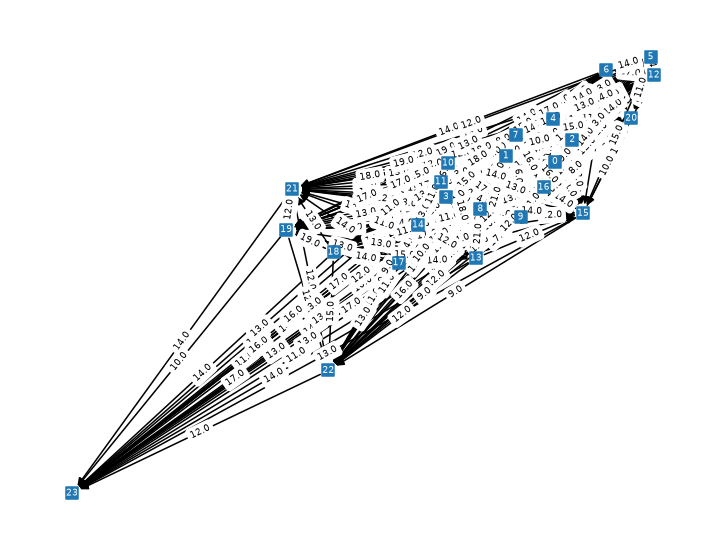

In [ ]:
# Reduce the graph before solving it, and check up front that it can be solved at all.
#
#   (a) isolated nodes  - no incoming and no outgoing edge
#   (b) source nodes    - outgoing edges only; a candidate START node
#   (c) sink nodes      - incoming edges only; a candidate END node
#   (d) small components- weakly connected components of 3 nodes or fewer carry too little
#                         layout information to contribute a meaningful Hamiltonian path,
#                         and are the only group actually removed
#
# Sources and sinks are valid: a Hamiltonian path can have one source as its first node
# and one sink as its last. The quantum reference state uses the same endpoint logic,
# falling back to minimum weighted in-/out-degree when needed.
#
# The graph is impossible if it has >= 2 sources, >= 2 sinks, or any isolated node (N > 1).
# These are necessary checks only; the solver must still determine whether a path exists.

# (a) isolated nodes: in-degree 0 and out-degree 0
isolated_nodes = []
print("Node\tIndegree\tOutdegree")
for node in overlap_graph.nodes():
    if overlap_graph.in_degree(node) == 0 and overlap_graph.out_degree(node) == 0:
        print(f"{node}\t{overlap_graph.in_degree(node)}\t\t{overlap_graph.out_degree(node)}")
        isolated_nodes.append(node)

# (b) source nodes: in-degree 0, out-degree > 0  -> candidate start node
print("-------- sources")
source_nodes = []
for node in overlap_graph.nodes():
    if overlap_graph.in_degree(node) == 0 and overlap_graph.out_degree(node) > 0:
        print(f"{node}\t{overlap_graph.in_degree(node)}\t\t{overlap_graph.out_degree(node)}")
        source_nodes.append(node)

# (c) sink nodes: in-degree > 0, out-degree 0  -> candidate end node
print("-------- sinks")
sink_nodes = []
for node in overlap_graph.nodes():
    if overlap_graph.in_degree(node) > 0 and overlap_graph.out_degree(node) == 0:
        print(f"{node}\t{overlap_graph.in_degree(node)}\t\t{overlap_graph.out_degree(node)}")
        sink_nodes.append(node)

# Feasibility pre-check, per the rule in the header comment.
feasible = True
if len(isolated_nodes) > 0 and len(overlap_graph.nodes()) > 1:
    print("INFEASIBLE: isolated nodes present:", isolated_nodes)
    feasible = False
if len(source_nodes) > 1:
    print("INFEASIBLE: more than one source, cannot all be the first node:", source_nodes)
    feasible = False
if len(sink_nodes) > 1:
    print("INFEASIBLE: more than one sink, cannot all be the last node:", sink_nodes)
    feasible = False
if feasible:
    print(f"feasibility pre-check passed: {len(source_nodes)} source(s), "
          f"{len(sink_nodes)} sink(s), {len(isolated_nodes)} isolated node(s)")
    print("reference-state seed -> start node:", source_nodes if source_nodes else "(none: use min weighted in-degree)")
    print("reference-state seed -> end node  :", sink_nodes if sink_nodes else "(none: use min weighted out-degree)")

# (d) small weakly connected components - the only nodes removed
components = list(nx.weakly_connected_components(overlap_graph))
for i, comp in enumerate(components):
    print(f"Component {i + 1}: {comp}")

small_components = [comp for comp in nx.connected_components(overlap_graph.to_undirected())
                    if 2 <= len(comp) <= 3]
small_component_nodes = [node for comp in small_components for node in comp]
print("nodes in small components:", small_component_nodes)

# NOTE: this is an alias, not a copy - reduced_graph and overlap_graph are the same
# object, so the removals below mutate overlap_graph too. Nothing afterwards needs the
# unreduced graph, so this is harmless here; be aware of it if you add a cell that does.
# Sinks and sources are deliberately NOT removed: on this graph the sink is the path's
# terminus and the source its start, so removing them would destroy the only path.
reduced_graph = overlap_graph

print("before removing", len(reduced_graph.nodes()))
print("before removing", len(reduced_graph.edges()))

for i in range(len(small_component_nodes)):
    reduced_graph.remove_node(small_component_nodes[i])

print("after removing", len(reduced_graph.nodes()))
print("after removing", len(reduced_graph.edges()))

show_wgraph(reduced_graph)

In [ ]:
# Relabel the retained nodes to a contiguous 0..N-1 range, which is what both the
# Hamiltonian path search and the quantum encoding expect. 
original_nodes = list(reduced_graph.nodes())
original_to_new = {original: new for new, original in enumerate(original_nodes)}
new_to_original = {new: original for original, new in original_to_new.items()}

relabelled_nodes = [original_to_new[v] for v in original_nodes]
relabelled_edges_with_weight = [(original_to_new[u], original_to_new[v], data)
                                for u, v, data in reduced_graph.edges(data=True)]
relabelled_edge_list = [[u, v] for u, v, _ in relabelled_edges_with_weight]

print("N=", relabelled_nodes)
print("edges=", relabelled_edge_list)

N= [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
edges= [[0, 1], [0, 5], [0, 6], [0, 7], [0, 10], [0, 12], [0, 15], [0, 16], [0, 13], [0, 9], [0, 22], [0, 2], [0, 20], [0, 18], [0, 19], [0, 8], [0, 17], [0, 11], [0, 14], [0, 21], [0, 3], [0, 23], [0, 4], [1, 10], [1, 9], [2, 3], [2, 4], [2, 5], [2, 13], [2, 17], [2, 14], [2, 18], [2, 1], [2, 23], [2, 12], [2, 21], [2, 10], [2, 7], [2, 8], [2, 16], [2, 9], [2, 15], [2, 20], [2, 6], [2, 11], [2, 22], [2, 19], [3, 13], [3, 18], [3, 4], [3, 1], [3, 5], [3, 10], [3, 12], [3, 15], [3, 9], [4, 5], [4, 12], [4, 1], [4, 15], [4, 10], [4, 13], [4, 9], [4, 18], [5, 13], [5, 18], [5, 1], [5, 10], [5, 9], [5, 12], [5, 15], [6, 3], [6, 17], [6, 4], [6, 13], [6, 22], [6, 18], [6, 23], [6, 5], [6, 19], [6, 12], [6, 15], [6, 7], [6, 1], [6, 10], [6, 16], [6, 20], [6, 9], [7, 3], [7, 4], [7, 5], [7, 13], [7, 12], [7, 18], [7, 15], [7, 16], [7, 1], [7, 10], [7, 20], [7, 9], [8, 9], [8, 11], [8, 14], [8, 15], [8, 2

In [ ]:
# Find the Hamiltonian path classically. This is the reference solution: it proves the
# subgraph is a valid instance before any solver time is spent on it
from functools import lru_cache


def find_hamiltonian_paths(N, edges, min_nodes):
    """Return all node sequences of length >= min_nodes visiting each node at most once."""
    graph = {i: set() for i in range(N)}
    for u, v in edges:
        graph[u].add(v)          # directed graph: do not add the reverse edge

    @lru_cache(None)
    def dfs(node, visited):
        if bin(visited).count('1') >= min_nodes:
            return [[node]]
        paths = []
        for neighbor in graph[node]:
            if not (visited & (1 << neighbor)):
                for path in dfs(neighbor, visited | (1 << neighbor)):
                    paths.append([node] + path)
        return paths

    hamiltonian_paths = []
    for start in range(N):
        hamiltonian_paths.extend(dfs(start, 1 << start))
    return hamiltonian_paths


N = len(relabelled_nodes)
MIN_NODES = N            # N for a true Hamiltonian path; N-1, N-2 ... to relax

paths = find_hamiltonian_paths(N, relabelled_edge_list, MIN_NODES)
print(f"Found {len(paths)} paths of at least {MIN_NODES} nodes:")
for path in paths:
    print(" -> ".join(map(str, path)))

Found 1 paths of at least 24 nodes:
0 -> 2 -> 8 -> 11 -> 14 -> 21 -> 6 -> 22 -> 19 -> 17 -> 23 -> 7 -> 16 -> 20 -> 3 -> 4 -> 5 -> 12 -> 15 -> 13 -> 18 -> 1 -> 10 -> 9


In [ ]:
# Map paths to original read IDs and rank them by total overlap weight.
# MIN_PATH_WEIGHT filters weak paths before contig generation.
MIN_PATH_WEIGHT = 50

paths_original_ids = []
path_weights = []
kept_path_indices = []

for j, path in enumerate(paths):
    original_vertex = [new_to_original[v] for v in path]
    print(original_vertex)
    paths_original_ids.append(original_vertex[:])

    total_weight = 0
    for i in range(len(original_vertex) - 1):
        edge_data = reduced_graph.get_edge_data(original_vertex[i], original_vertex[i + 1])
        total_weight += edge_data['weight'] if edge_data and 'weight' in edge_data else 0

    if total_weight >= MIN_PATH_WEIGHT:
        path_weights.append(total_weight)
        kept_path_indices.append(j)
        print(j, total_weight)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
0 335.0


In [ ]:
# Export the weighted adjacency matrix - the single artefact handed to the quantum stage.
# adjacency[i, j] is the overlap score of edge i -> j and 0 where no edge exists. nodelist
# is reduced_graph.nodes
original_edge_list = [[u, v, data['weight']] for u, v, data in reduced_graph.edges(data=True)]
print("N=", relabelled_nodes)
print("relabelled edges with weights:", relabelled_edges_with_weight)
print("edge list (relabelled ids):", relabelled_edge_list)
print("edge list (original read ids + weight):", original_edge_list)

adjacency = nx.to_numpy_array(reduced_graph, nodelist=reduced_graph.nodes)
print("\nadjacency matrix", adjacency.shape)
print(adjacency)

np.savetxt("adjacency_matrix.csv", adjacency, delimiter=",", fmt="%g")
print("\nwrote adjacency_matrix.csv")

N= [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
relabelled edges with weights: [(0, 1, {'weight': np.float64(14.0)}), (0, 5, {'weight': np.float64(14.0)}), (0, 6, {'weight': np.float64(15.0)}), (0, 7, {'weight': np.float64(16.0)}), (0, 10, {'weight': np.float64(11.0)}), (0, 12, {'weight': np.float64(18.0)}), (0, 15, {'weight': np.float64(15.0)}), (0, 16, {'weight': np.float64(14.0)}), (0, 13, {'weight': np.float64(13.0)}), (0, 9, {'weight': np.float64(14.0)}), (0, 22, {'weight': np.float64(13.0)}), (0, 2, {'weight': np.float64(16.0)}), (0, 20, {'weight': np.float64(13.0)}), (0, 18, {'weight': np.float64(12.0)}), (0, 19, {'weight': np.float64(16.0)}), (0, 8, {'weight': np.float64(13.0)}), (0, 17, {'weight': np.float64(13.0)}), (0, 11, {'weight': np.float64(11.0)}), (0, 14, {'weight': np.float64(10.0)}), (0, 21, {'weight': np.float64(10.0)}), (0, 3, {'weight': np.float64(14.0)}), (0, 23, {'weight': np.float64(18.0)}), (0, 4, {'weight': np.float64